# Imports

##### standard python libraries

In [9]:
import polars as pl
import adbc_driver_postgresql.dbapi as adbc_api
import re

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import matplotlib.cm as cm


In [2]:
import warnings
warnings.filterwarnings('ignore')

##### Custom Libraries

In [3]:
import psql_utilities as psql_utl

### Set Paths

In [4]:
### path to configuration file of database
path_conf_file = './../../config/database.ini'

### Database Connection

In [5]:
db_config = psql_utl.load_config(path_conf_file)
### connect to the databse (polars adbc)
conn = adbc_api.connect(db_config['db_uri'])

## Retrieve simulation run parameters of BS scenarios

In this notebook we use simulation run parameters associated to BS-type scearios to plot the location of BS scenarios on a map.


### setup

##### read query from file

In [6]:
query_params_ps = open("./query_params_bs.sql", "r")
query_params_ps = query_params_ps.read()

##### set input variables

### query result

##### run query with polars

In [7]:
df_sr_params_bs = pl.read_database_uri(query_params_ps,engine='connectorx',uri=db_config['db_uri'],partition_num=6)
df_sr_params_bs

sr_id,sr_path,scen_name,fk_sr_id,seismicity_type,magnitude,manning_coeff,fault_centre_lon,fault_centre_lat,fault_centre_depth,fault_lenght,fault_width,strike,dip,rake,slip
str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""sr_1""","""CT-SR_M100/BS_001/E01267N3753E…","""E01267N3753E01646N3535-BS-M792…","""sr_1""","""BS""",7.92,0.01,15.3075,37.3774,8.187,146.004797,32.749,202.5,30.0,270.0,6.221125
"""sr_2""","""CT-SR_M100/BS_001/E01522N3585E…","""E01522N3585E03578N2685-BS-M792…","""sr_2""","""BS""",7.92,0.01,18.0126,33.7801,15.387,146.004797,32.749,67.5,70.0,90.0,6.221125
"""sr_3""","""CT-SR_M100/BS_001/E01267N3753E…","""E01267N3753E01646N3535-BS-M809…","""sr_3""","""BS""",8.09,0.01,15.0245,37.3774,32.398,183.454046,38.135,112.5,70.0,90.0,7.525559
"""sr_4""","""CT-SR_M100/BS_001/E01446N4259E…","""E01446N4259E02038N3783-BS-M732…","""sr_4""","""BS""",7.32,0.01,19.8065,38.5016,8.792,63.069594,18.712,157.5,70.0,270.0,3.089911
"""sr_5""","""CT-SR_M100/BS_001/E01522N3585E…","""E01522N3585E03578N2685-BS-M774…","""sr_5""","""BS""",7.74,0.01,18.5536,33.7801,6.919,113.440739,27.677,67.5,30.0,90.0,5.040772
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""sr_25037""","""CT-SR_M100/BS_001/E01446N4259E…","""E01446N4259E02038N3783-BS-M774…","""sr_25037""","""BS""",7.74,0.01,18.8065,39.1761,6.919,113.440739,27.677,292.5,30.0,90.0,5.040772
"""sr_25038""","""CT-SR_M100/BS_001/E01522N3585E…","""E01522N3585E03578N2685-BS-M792…","""sr_25038""","""BS""",7.92,0.01,18.6782,34.4546,12.544,146.004797,32.749,22.5,50.0,90.0,6.221125
"""sr_25039""","""CT-SR_M100/BS_001/E01522N3585E…","""E01522N3585E03578N2685-BS-M732…","""sr_25039""","""BS""",7.32,0.01,16.9211,35.3539,7.167,63.069594,18.712,247.5,50.0,90.0,3.089911


### BS Event Location

In [8]:
df_bs_hypo = df_sr_params_bs.select('scen_name','fault_centre_lon','fault_centre_lat','fault_centre_depth')
df_bs_hypo

scen_name,fault_centre_lon,fault_centre_lat,fault_centre_depth
str,f64,f64,f64
"""E01267N3753E01646N3535-BS-M792…",15.3075,37.3774,8.187
"""E01522N3585E03578N2685-BS-M792…",18.0126,33.7801,15.387
"""E01267N3753E01646N3535-BS-M809…",15.0245,37.3774,32.398
"""E01446N4259E02038N3783-BS-M732…",19.8065,38.5016,8.792
"""E01522N3585E03578N2685-BS-M774…",18.5536,33.7801,6.919
…,…,…,…
"""E01446N4259E02038N3783-BS-M774…",18.8065,39.1761,6.919
"""E01522N3585E03578N2685-BS-M792…",18.6782,34.4546,12.544
"""E01522N3585E03578N2685-BS-M732…",16.9211,35.3539,7.167


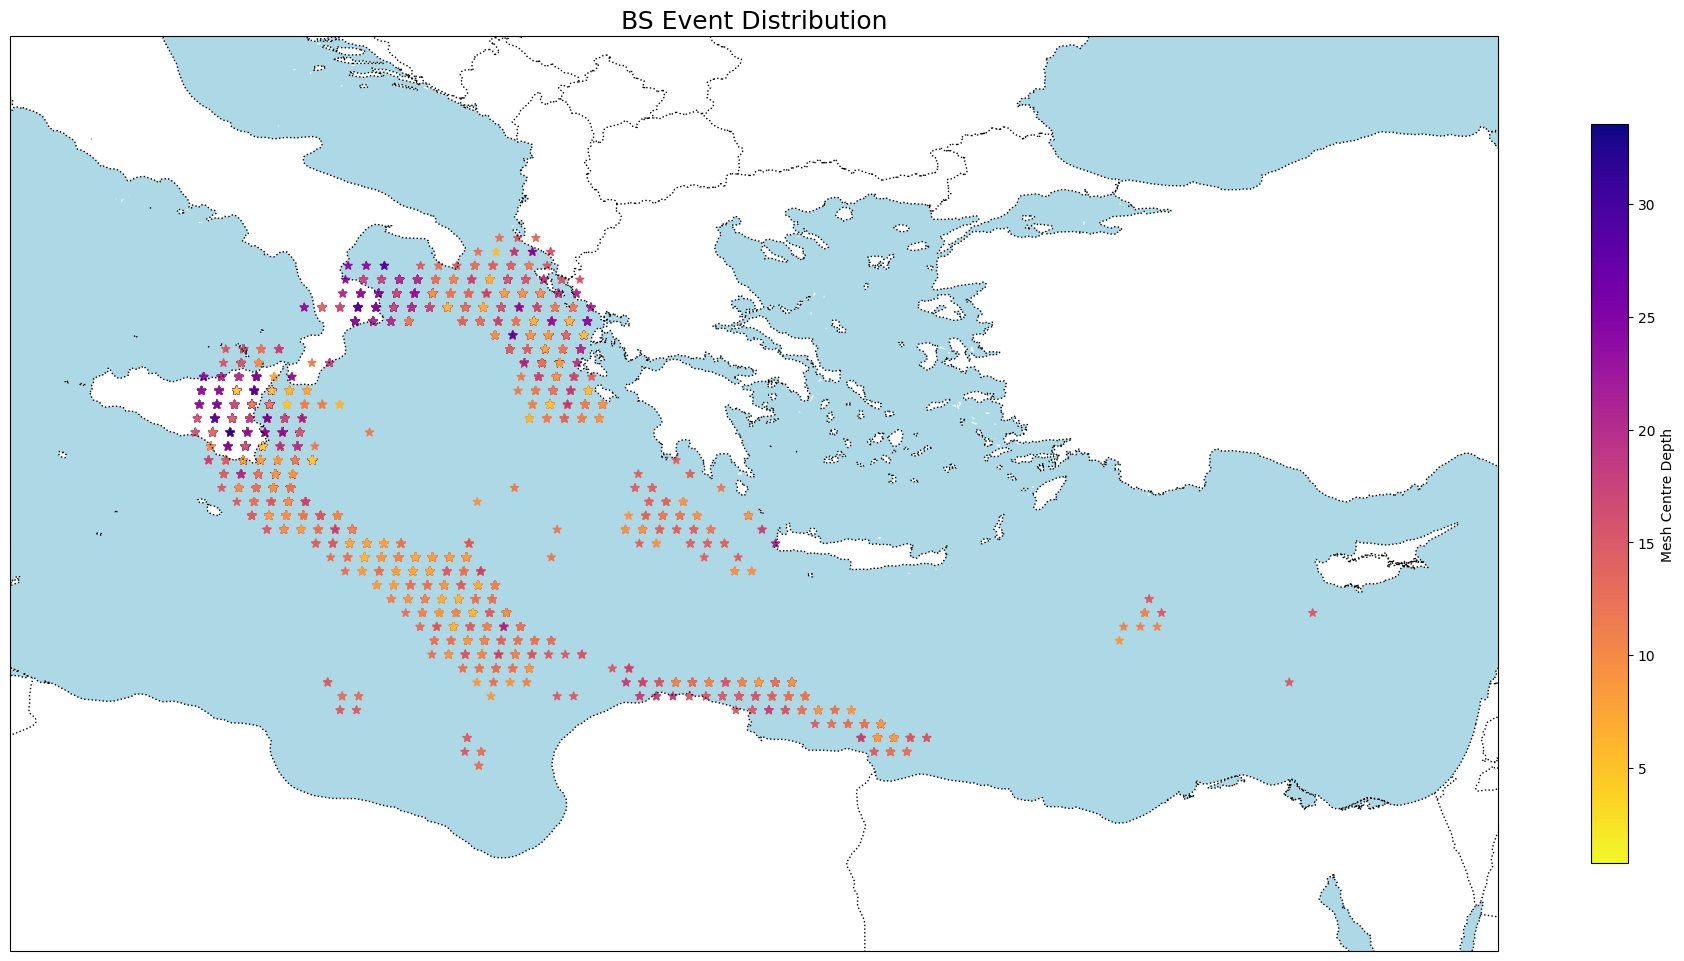

In [13]:
fig, ax = plt.subplots(
            figsize=(24, 12),
            subplot_kw={'projection': ccrs.PlateCarree()}
        )

proj = ccrs.PlateCarree()
ax.add_feature(cfeature.COASTLINE,linestyle=':')
ax.add_feature(cfeature.BORDERS,linestyle=':')
#ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='lightblue')

cmap_viridis_reversed = plt.get_cmap('plasma').reversed()
#
scatter_bs = ax.scatter(df_bs_hypo['fault_centre_lon'], df_bs_hypo['fault_centre_lat'], c=df_bs_hypo['fault_centre_depth'],cmap=cmap_viridis_reversed,
            marker='*', 
            #s = 5 + (list_events_mag**2) * 3,
            #norm=PowerNorm(gamma=0.7),
            transform=proj)
#ax.set_extent([-6.5, 39, 30, 45])
ax.set_extent([df_bs_hypo['fault_centre_lon'].min()-3,df_bs_hypo['fault_centre_lon'].max()+3, df_bs_hypo['fault_centre_lat'].min()-3, df_bs_hypo['fault_centre_lat'].max()+3])
ax.set_title('BS Event Distribution',fontsize=18)
#
fig.colorbar(scatter_bs, ax=ax, orientation='vertical', label='Mesh Centre Depth', shrink=0.8, pad=0.05)